In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = sns.load_dataset("titanic")  # 891 errenkada × 15 zutabe
# edo fitxategia igo eta df = pd.read_csv("titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
# Joera zentraleko neurriak: batezbestekoa, mediana eta moda (balio ohikoena)
print("age -> batezbestekoa:", round(df["age"].mean(), 2),
"| mediana:", df["age"].median(),
"| moda:", df["age"].mode()[0])

age -> batezbestekoa: 29.7 | mediana: 28.0 | moda: 24.0


In [3]:
# Zer egiten du hurrengo kodeak?
# Sakabanaketa-neurriak kalkulatzen ditu: desbideratze estandarra (std) eta Q1/Q3 kuartilak.
# Q1=20.1 -> bidaiarien %25ek 20 urte baino gutxiago; Q3=38 -> %75ek 38 baino gutxiago.
print("age -> desb:", round(df["age"].std(), 2),
"| Q1:", df["age"].quantile(0.25),
"| Q3:", df["age"].quantile(0.75))

age -> desb: 14.53 | Q1: 20.125 | Q3: 38.0


In [4]:
# Zer egiten du hurrengo kodeak?
# fare-ren forma neurtzen du: asimetria (skew) eta kurtosia, eta batezbestekoa vs mediana konparatzen ditu.
# Asimetria 4.79 > 0 -> eskuinerantz isats luzea (txartel oso garesti gutxi batzuk).
# Kurtosia 33.4 -> balio muturreko asko (outlierrak). Horregatik batezbestekoa (32.2) mediana (14.45) baino askoz handiagoa da.
print("fare -> asimetria:", round(df["fare"].skew(), 2),
"| kurtosia:", round(df["fare"].kurt(), 2))
print("fare -> batezbestekoa:", round(df["fare"].mean(),2),
"| mediana:", df["fare"].median())

fare -> asimetria: 4.79 | kurtosia: 33.4
fare -> batezbestekoa: 32.2 | mediana: 14.4542


In [5]:
# describe(): count, mean, std, min, kuartilak eta max zutabe bakoitzeko
df[['age','fare']].describe().round(2)

,age,fare
count,714.00,891.00
mean,29.70,32.20
std,14.53,49.69
min,0.42,0.00
25%,20.12,7.91
50%,28.00,14.45
75%,38.00,31.00
max,80.00,512.33


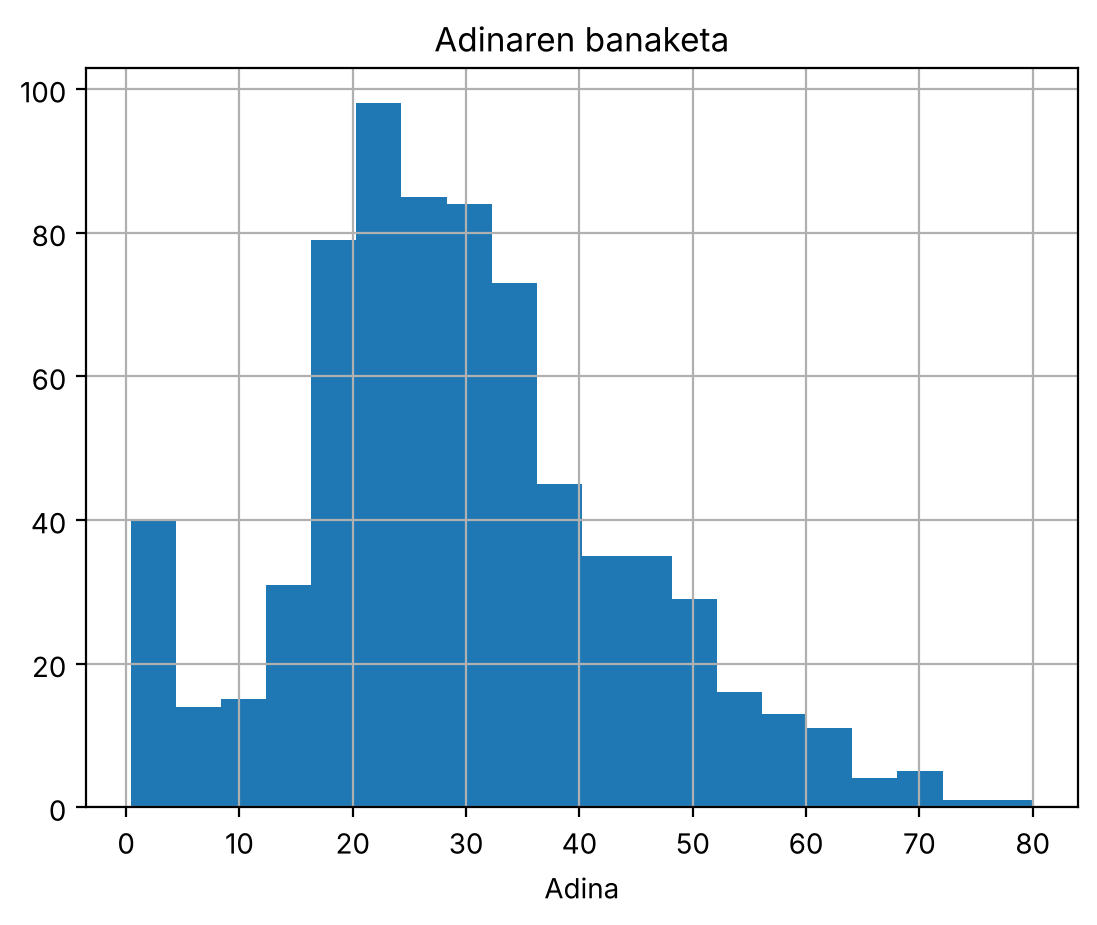

In [6]:
# Adinaren histograma: 20 tartetan zenbat bidaiari dauden. Gehienak 20-40 urte artean.
df["age"].hist(bins=20)
plt.title("Adinaren banaketa")
plt.xlabel("Adina")
plt.show()

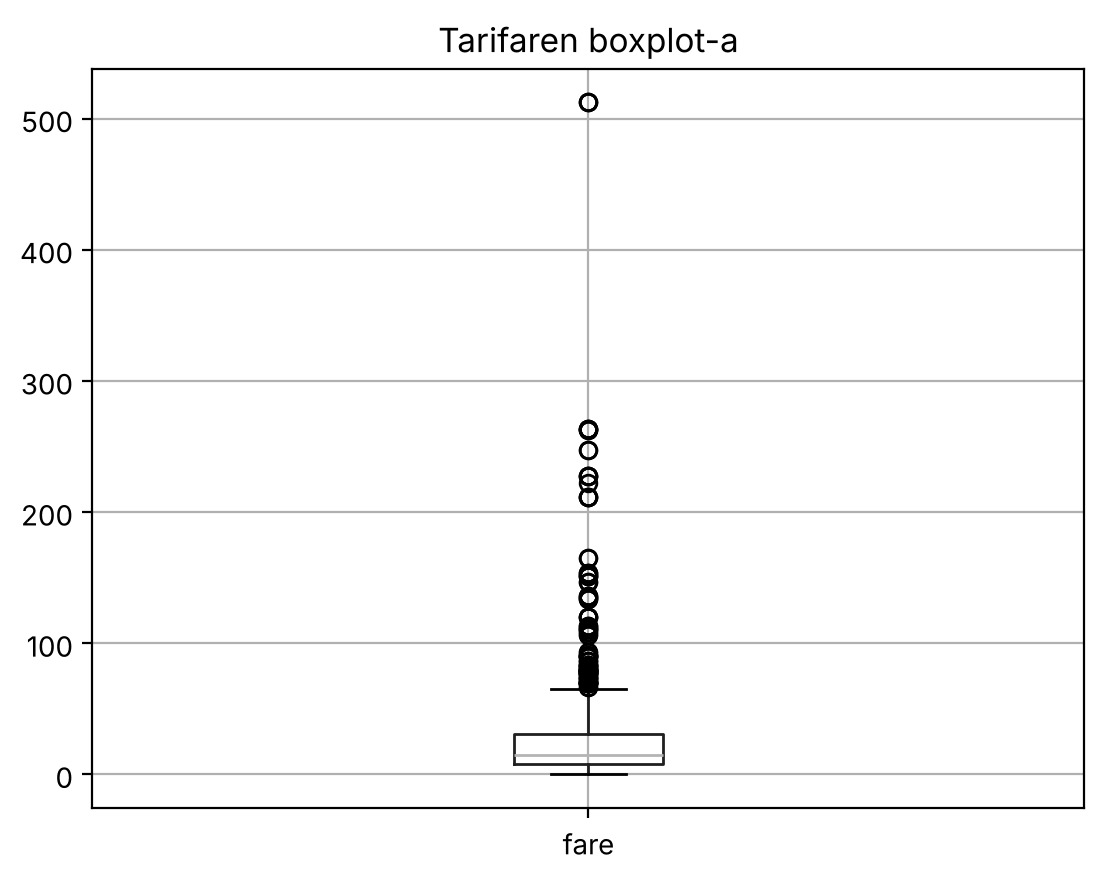

In [7]:
# Zer egiten du hurrengo kodeak?
# fare-ren boxplot-a marrazten du: kutxa = Q1-Q3 (IQR), barruko marra = mediana,
# bibotea = 1.5*IQR-raino, eta haratago dauden puntuak = outlierrak (adib. 512).
df.boxplot(column="fare")
plt.title("Tarifaren boxplot-a")
plt.show()

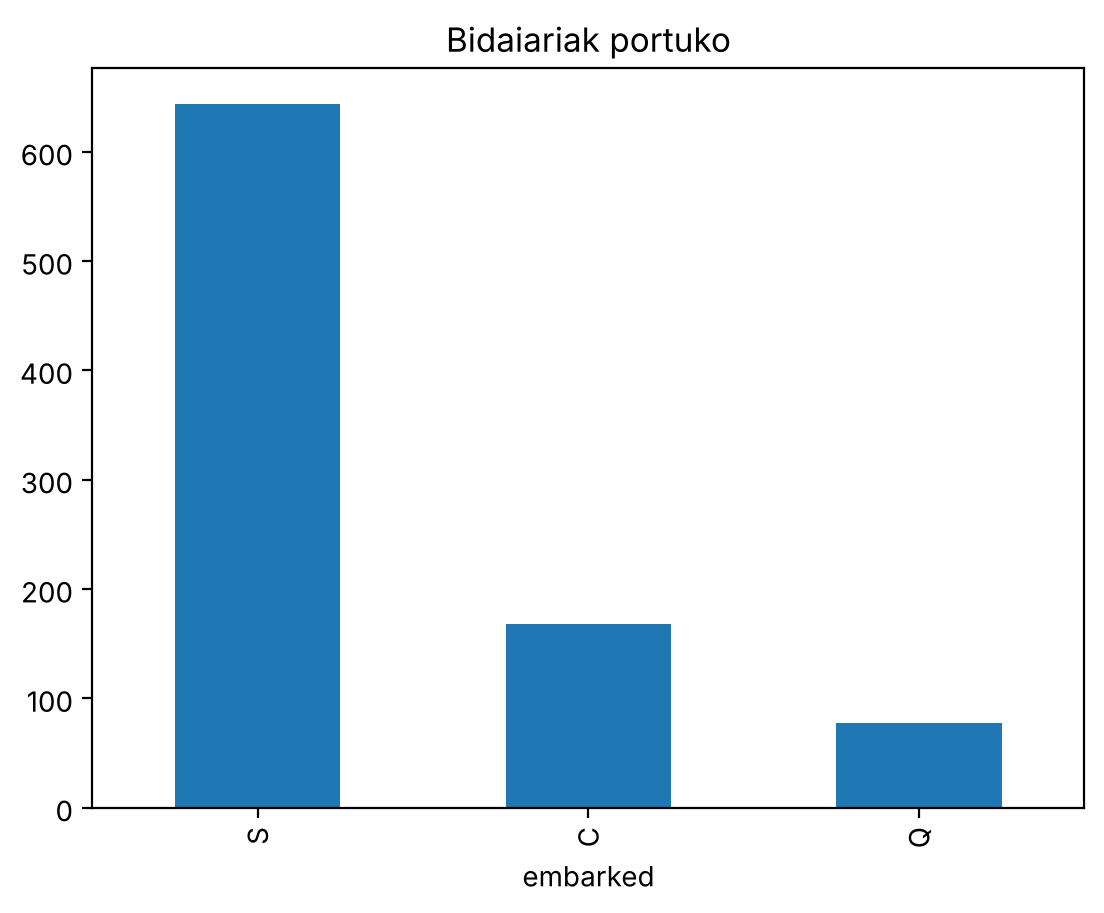

In [8]:
# Zer egiten du hurrengo kodeak?
# Portu bakoitzetik (S, C, Q) zenbat bidaiari igo ziren zenbatzen du (value_counts) eta barra-grafikoan erakusten du.
# Southampton (S) da nagusia.
df["embarked"].value_counts().plot(kind="bar")
plt.title("Bidaiariak portuko")
plt.show()

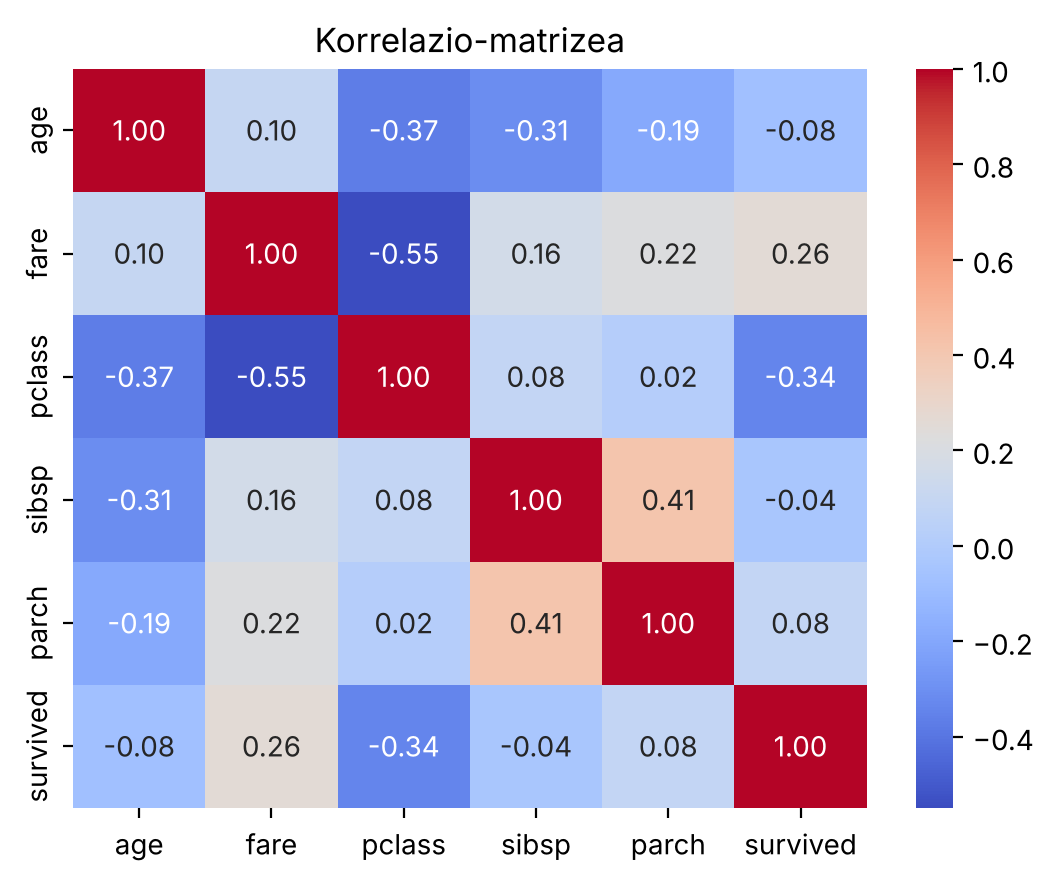

In [9]:
# Zer egiten du hurrengo kodeak?
# Aldagai numerikoen arteko korrelazio-matrizea (Pearson, -1 eta 1 artean) kalkulatu eta heatmap gisa marrazten du.
# Adib: pclass eta fare -0.55 (klase txarragoa -> txartel merkeagoa); survived eta pclass -0.34; survived eta fare +0.26.
num = df[["age", "fare", "pclass", "sibsp", "parch",
"survived"]]
sns.heatmap(num.corr(), annot=True, cmap="coolwarm",
fmt=".2f")
plt.title("Korrelazio-matrizea")
plt.show()

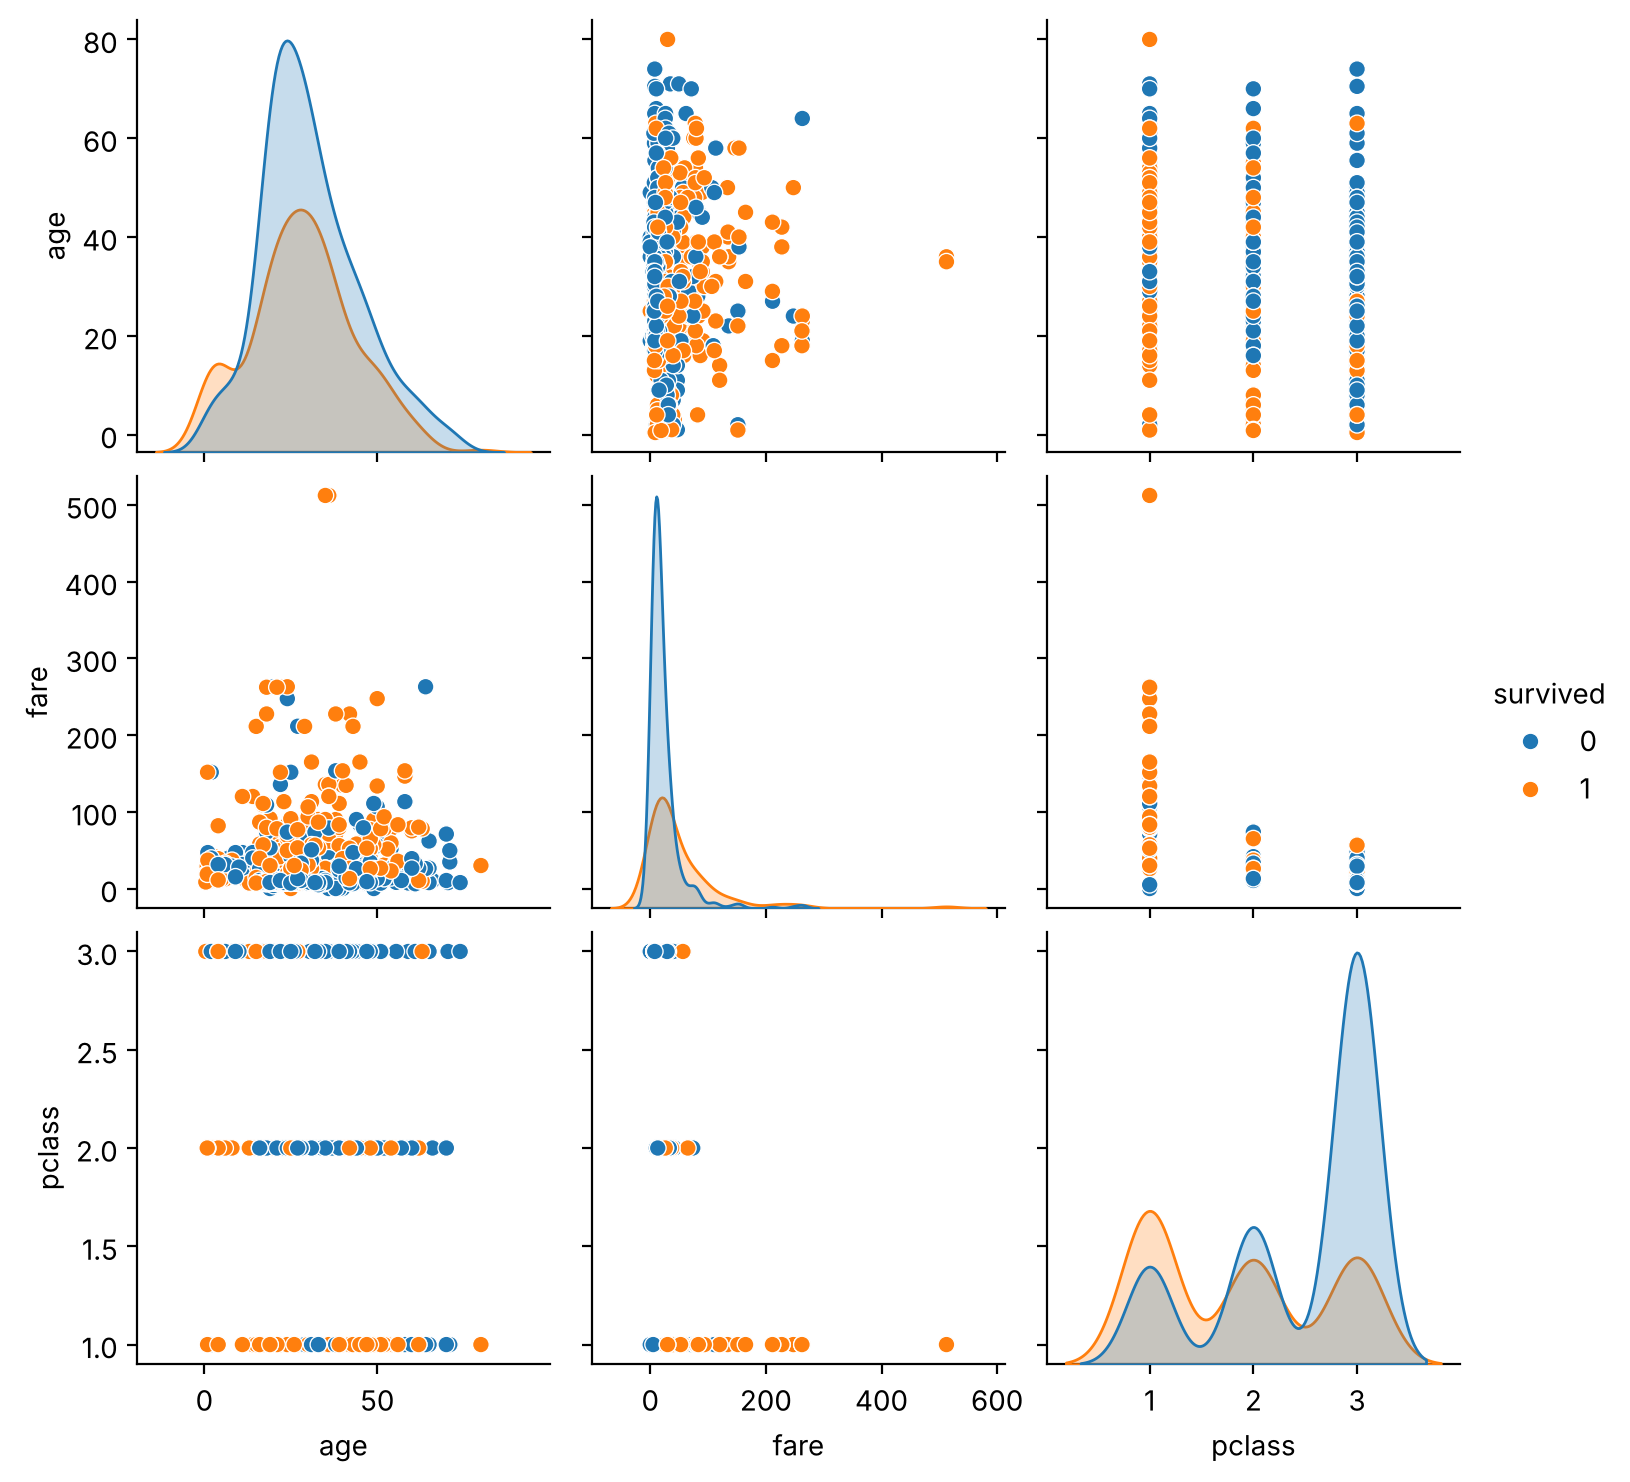

In [10]:
# Zer egiten du hurrengo kodeak?
# Pairplot: aldagai bikote guztien scatter-ak eta diagonalean banaketa bakoitza,
# survived-en arabera koloreztatuta (hue). dropna() -> age nuluak dituzten errenkadak kentzen ditu marrazteko.
sns.pairplot(df[["age", "fare", "pclass",
"survived"]].dropna(), hue="survived")
plt.show()